# Meta-learning with CAVIA 

This notebook shows how to implement CAVIA, a variant of Model Agnostic Meta-Learning (MAML) for few-shot adaptation on sinusoidal regression tasks. This example follows section 5.1.1 of the "Fast Context Adaptation via Meta-Learning" paper by Zintgraf et al., 2019.


We will start by importing the relevant dependencies.

In [1]:
from functools import partial

import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jr
import jax.tree as jt
import metatopia as mtp
import optax
from metatopia.dataset.sine import sin_task_iterator
from metatopia.models import ContextMLP


jax.config.update("jax_enable_x64", True)

[INFO 22-01 13:10:55] metatopia: Running version 0.0.2 on the GPU.


## Data generation
First, let's understand how we generate our sinusoidal tasks. Each task represents a different sinusoidal function with unique amplitude and phase. At meta-training, we will adapt the neural network to fit a set of 10 training points, and evaluate its loss on a validation test set of other 10 points sampled from the same tasks. We will use the `sin_task_iterator` function to generate the tasks.

In [2]:
metatrain_seed = 0
metatest_seed = 1
num_points = 10

# [NOTE] We use the same seed to ensure train and validation
train_iterator_fn = partial(
    sin_task_iterator,
    num_points=num_points,
    seed=metatrain_seed,
    split="train",
)
validation_iterator_fn = partial(
    sin_task_iterator,
    num_points=num_points,
    seed=metatrain_seed,
    split="val",
)

test_iterator_fn = partial(
    sin_task_iterator, num_points=num_points, seed=metatest_seed, split="val"
)

## Neural network setup
Now, let's create a simple neural network with concatenation-based conditioning.

In [3]:
model = ContextMLP(
    in_features=1,  # Input dimension (x coordinate)
    hidden_features=40,  # Hidden layer size
    hidden_layers=2,  # Number of hidden layers
    out_features=1,  # Output dimension (y coordinate)
    context_features=4,
    key=jr.key(42),
)

## Loss functions and optimizers
Next, we define the loss functions and optimizers for inner and outer learning loops. For the loss functions, we adhere to the format `params, static, sample) -> (loss, metrics)`.

In [4]:
def mse_loss_fn(params, static, sample):
    model = eqx.combine(params, static)
    pred = jax.vmap(model)(sample["x"])
    return jnp.mean((sample["y"] - pred) ** 2)


def loss_fn(params, static, sample):
    loss = mse_loss_fn(params, static, sample)
    return loss, None


inner_loss_fn = loss_fn
outer_loss_fn = loss_fn
inner_opt = optax.sgd(1e-2)
outer_opt = optax.adam(1e-3)

## Create learner filters
In CAVIA, we only adapt the context parameters in the inner loop, and update the MLP parameters in the outer loop. To achieve this, we create filters for the inner and outer loop. The filters are PyTrees of booleans with the same structure as the base model.



In [5]:
base_filter = jt.map(lambda _: False, model)
learnable_filter = jt.map(eqx.is_array, model)

inner_filter = jt.map(eqx.is_array, model.context_params)
inner_filter = eqx.tree_at(lambda tree: tree.context_params, base_filter, inner_filter)

outer_filter = eqx.tree_at(lambda tree: tree.context_params, learnable_filter, False)

## Create a meta-learner
Now, we will create a meta-learner, using the `MAML` base class, and run it for $10,000$ outer steps. The block below will take a while to run.

In [6]:
meta_learner = mtp.learners.MAML(
    model,
    inner_opt,
    outer_opt,
    inner_loss_fn,
    outer_loss_fn,
    inner_filter,
    outer_filter,
)

meta_learned_model, meta_losses, metrics = mtp.learners.meta_learn(
    meta_learner=meta_learner,
    train_iterator_fn=train_iterator_fn,
    validation_iterator_fn=validation_iterator_fn,
    batch_size=25,
    outer_steps=10_000,
    inner_steps=1,
    log_every_n=1_000,
)

[INFO 22-01 13:11:01] metatopia: Step: 0     Loss: 4.29083
[INFO 22-01 13:11:20] metatopia: Step: 1000  Loss: 0.92794
[INFO 22-01 13:11:41] metatopia: Step: 2000  Loss: 0.50631
[INFO 22-01 13:12:04] metatopia: Step: 3000  Loss: 0.23732
[INFO 22-01 13:12:23] metatopia: Step: 4000  Loss: 0.35109
[INFO 22-01 13:12:44] metatopia: Step: 5000  Loss: 0.49912
[INFO 22-01 13:13:02] metatopia: Step: 6000  Loss: 0.30708
[INFO 22-01 13:13:25] metatopia: Step: 7000  Loss: 0.17452
[INFO 22-01 13:13:46] metatopia: Step: 8000  Loss: 0.34440
[INFO 22-01 13:14:04] metatopia: Step: 9000  Loss: 0.27143
[INFO 22-01 13:14:26] metatopia: Step: 9999  Loss: 0.27853


## Evaluate the meta-learned model
At meta-testing, we consider 1000 sinusoidal tasks with 10 points each and evaluate the MSE over 100 equally spaced test points. 

In [7]:
def evaluate_models(meta_learner, base_model, meta_learned_model, test_batch):
    """Compare meta-learned model vs standard model on new tasks."""

    # Get trainable parameters for both models
    params_meta, static_meta = eqx.partition(
        meta_learned_model, meta_learner.inner_filter
    )
    params_std, static_std = eqx.partition(base_model, meta_learner.inner_filter)

    # Adapt models to test tasks (1 gradient step)
    params_meta, _, _ = meta_learner.adapt(params_meta, static_meta, test_batch, 1)
    params_std, _, _ = meta_learner.adapt(params_std, static_std, test_batch, 1)

    @partial(jax.vmap, in_axes=(0, None, None))
    def apply_model(params, static, X):
        model = eqx.combine(params, static)
        return jax.vmap(model)(X)

    #  We measure the performance across 100 points
    X = jnp.linspace(-5, 5, 100).reshape(-1, 1)

    Ys0 = apply_model(params_std, static_std, X)
    Ys = apply_model(params_meta, static_meta, X)

    def get_gt_sinusoid(amp, phase, X):
        return amp * jnp.sin(X + phase)

    gt = jax.vmap(get_gt_sinusoid, in_axes=(0, 0, None))(
        test_batch["amp"], test_batch["phase"], X
    )

    mean_loss_meta = jnp.mean((Ys - gt) ** 2)
    mean_loss_std = jnp.mean((Ys0 - gt) ** 2)

    # Print losses
    print(f"Meta-learned MSE: {mean_loss_meta:.4f}")
    print(f"Standard MSE:     {mean_loss_std:.4f}")

    return X, Ys, Ys0


# Evaluate the model
num_test_tasks = 1000
test_batch = next(test_iterator_fn(num_test_tasks))

X, Ys, Ys0 = evaluate_models(meta_learner, model, meta_learned_model, test_batch)

Meta-learned MSE: 0.2237
Standard MSE:     4.0915


## Plot results
We compare adaptation to test tasks with a single adaptation step, demonstrating how the meta-learned approach better captures the underlying sine pattern in the tasks, even whn using just 10 points for adaptation. We also show how meta-loss evolves throughout the training.
"""

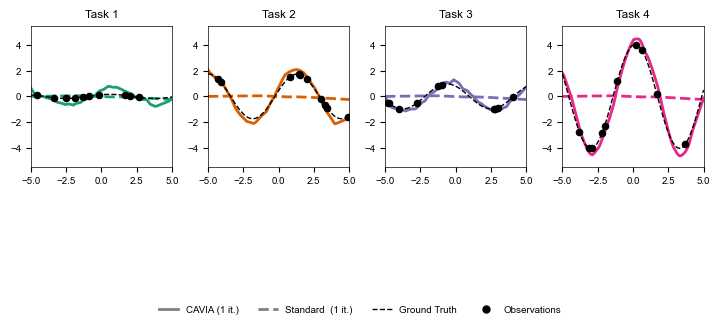

In [10]:
mtp.utils.plot_sinusoids(
    X, Ys, Ys0, test_batch, algo_name="CAVIA", n_plots=4, n_steps=1
)

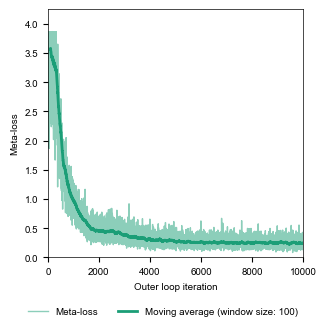

In [11]:
mtp.utils.plot_meta_losses(meta_losses)